<a href="https://colab.research.google.com/github/Marypery7/eda-netflix-pandas/blob/main/Peliculas_y_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Importar librerias



In [ ]:
#Importamos las librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Cargar csv

In [ ]:
# Cargamos el archivo CSV desde GitHub
url = "https://raw.githubusercontent.com/Marypery7/eda-netflix-pandas/main/netflix_titles%202.csv"

df = pd.read_csv(url)

# Mostramos las primeras filas
display(df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


3.Limpar y organizar los datos

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Diagnostico y limpieza de datos ausentes

In [ ]:
print("comprobamos los datos ausentes o incompletos")

comprobamos los datos ausentes o incompletos


In [ ]:
print(df.isnull().sum())# Comprobammos cuantos valores falyan en cada columna

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


Rellenamos los datos ausentes con un texto identificable(NO hemos descubierto la informacion que faltaba,solo indicamos que no esta disponible)

In [ ]:
df["country"] = df["country"].fillna("Desconocido")
df["cast"] = df["cast"].fillna("Desconocido")
df["director"] = df["director"].fillna("Desconocido")
df["date_added"] = df["date_added"].fillna("Desconocido")
df['duration'] = df['duration'].fillna('Desconocido')
df['rating'] = df['rating'].fillna('Desconocido')


● ¿Hay más películas o series?







/tmp/ipykernel_1068/3779231856.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='pastel')


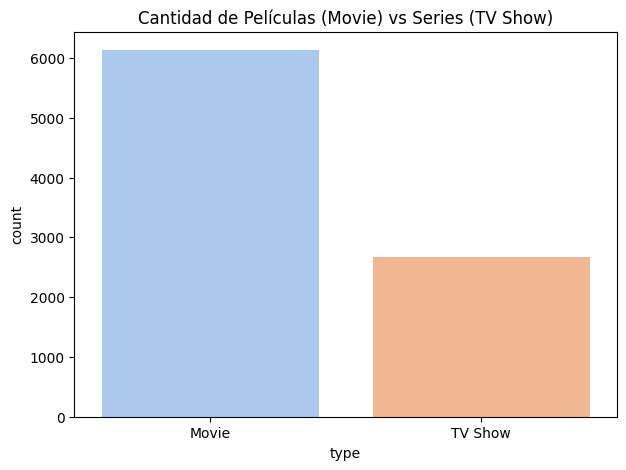

In [ ]:
plt.figure(figsize=(7, 5))  #Creamos un grafico de 7 pulgadas de ancho por 5 de alto

sns.countplot(data=df, x='type', palette='pastel') #Contamos automáticamente cuántos elementos hay de cada tipo y los ponemos en barras con tonos pastel

plt.title('Cantidad de Películas (Movie) vs Series (TV Show)')#  Añadimos el título principal en la parte superior del gráfico para identificarlo

plt.show()#Nos muestra el grafico terminado.


● ¿Qué géneros aparecen más?






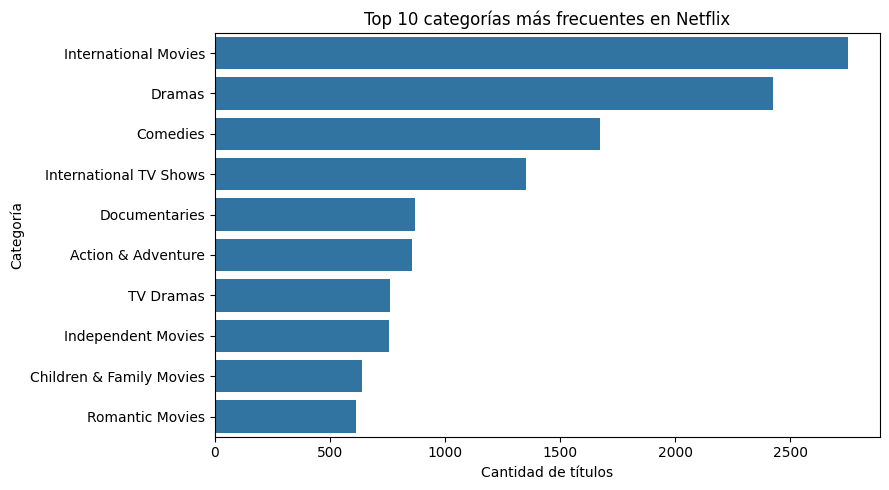

In [ ]:

# Separamos las categorías que aparecen juntas
generos = df["listed_in"].dropna().str.split(", ").explode()

# Eliminamos espacios sobrantes
generos = generos.str.strip()

# Contamos las 10 categorías más frecuentes
top_generos = generos.value_counts().head(10)

# Creamos el gráfico
plt.figure(figsize=(9, 5))
sns.barplot(x=top_generos.values, y=top_generos.index)

plt.title("Top 10 categorías más frecuentes en Netflix")
plt.xlabel("Cantidad de títulos")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()



● ¿Cómo ha cambiado el número de títulos por año?


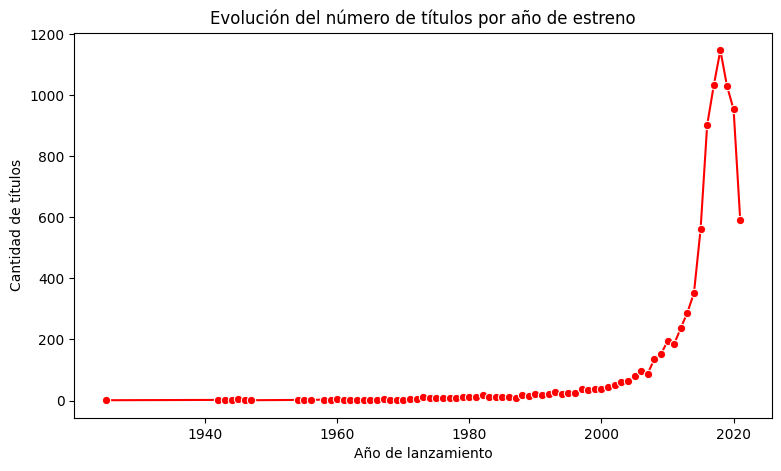

In [ ]:
titulos_por_año = df['release_year'].value_counts() #Contamos cuantas producciones se estrenaron en cada año

plt.figure(figsize=(9, 5))#Creamos la grafica

sns.lineplot(x=titulos_por_año.index, y=titulos_por_año.values, marker='o', color='red')#Dibujamos una línea conectando los años (eje X) con sus totales (eje Y) usando círculos pequeños ('o') en los puntos

plt.title('Evolución del número de títulos por año de estreno') #Anadimos el titulo del grafico

plt.xlabel('Año de lanzamiento')# Añadimos el texto explicativo debajo del eje horizontal (X)

plt.ylabel('Cantidad de títulos')# Añadimos el texto explicativo debajo del eje vertical (Y)

plt.show()# Nos muestra el grafico en pantalla


● ¿Qué países tienen más producciones en el catálogo?

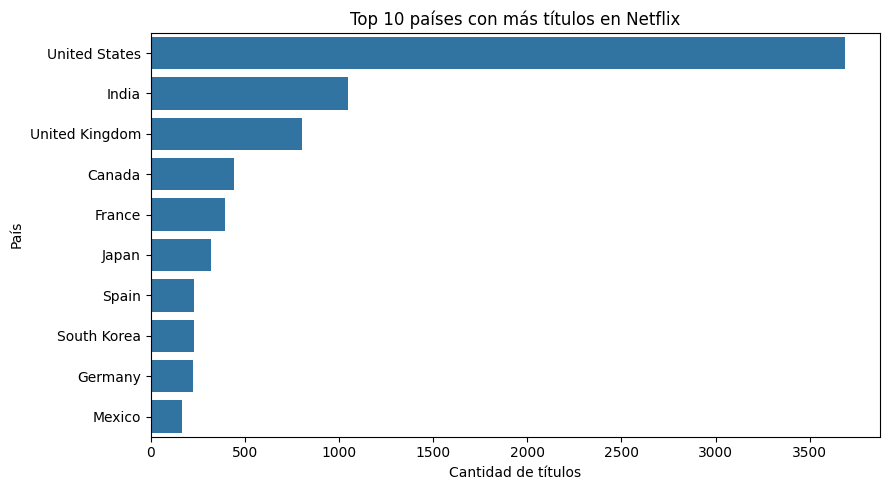


TOP 3 PAÍSES
country
United States     3689
India             1046
United Kingdom     804
Name: count, dtype: int64


In [31]:

# Contamos los títulos por país
paises = df["country"].dropna().str.split(", ").explode()

# Quitamos los valores desconocidos
paises = paises[paises != "Desconocido"]

# Mostramos los 10 países con más títulos
top_paises = paises.value_counts().head(10)

# Creamos el gráfico
plt.figure(figsize=(9, 5))
sns.barplot(x=top_paises.values, y=top_paises.index)
plt.title("Top 10 países con más títulos en Netflix")
plt.xlabel("Cantidad de títulos")
plt.ylabel("País")
plt.tight_layout()
plt.show()
print("\nTOP 3 PAÍSES")
print(top_paises.head(3))

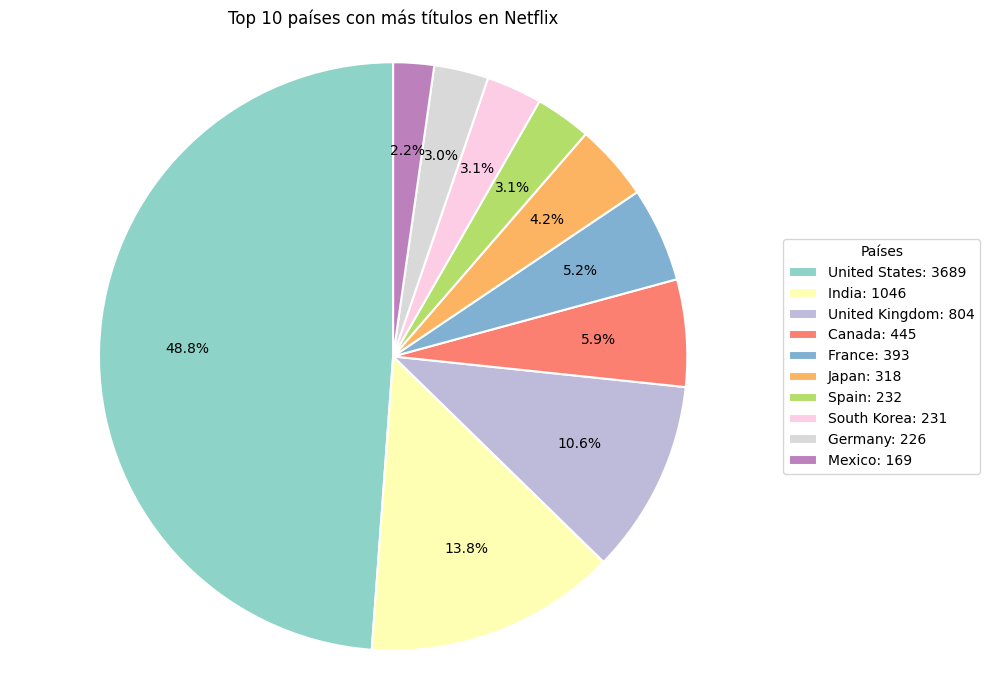

In [ ]:
import matplotlib.pyplot as plt

# Contamos los títulos por país
paises = df["country"].dropna().str.split(", ").explode()

# Quitamos los valores desconocidos
paises = paises[paises != "Desconocido"]

# Top 10 países
top_paises = paises.value_counts().head(10)

# Creamos el gráfico
fig, ax = plt.subplots(figsize=(10, 7))

colores = plt.cm.Set3.colors

wedges, texts, autotexts = ax.pie(
    top_paises.values,
    autopct="%1.1f%%",
    startangle=90,
    colors=colores,
    pctdistance=0.7,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

# Leyenda con nombres y cantidades
ax.legend(
    wedges,
    [f"{pais}: {cantidad}" for pais, cantidad
     in zip(top_paises.index, top_paises.values)],
    title="Países",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title("Top 10 países con más títulos en Netflix")
ax.axis("equal")

plt.tight_layout()
plt.show()

Comprobación final de los resultados

In [ ]:
print("TIPOS DE TÍTULOS")
print(df["type"].value_counts())

print("\nTOP 3 GÉNEROS")
print(top_generos.head(3))

print("\nTOP 3 PAÍSES")
print(top_paises.head(3))

TIPOS DE TÍTULOS
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

TOP 3 GÉNEROS
listed_in
International Movies    2752
Dramas                  2427
Comedies                1674
Name: count, dtype: int64

TOP 3 PAÍSES
country
United States     3689
India             1046
United Kingdom     804
Name: count, dtype: int64
